In [ ]:
#Assignment 1
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# PCA
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

# Evaluation
from sklearn.metrics import silhouette_score

In [ ]:
wine = pd.read_csv('/content/wine.csv')

wine.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [ ]:
wine.info()

wine.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [ ]:
#Business Problem
'''Business Objective

To reduce dimensions in wine chemical data and identify meaningful clusters of wines.'''

#Business Constraints
'''High-dimensional data increases complexity.
Clustering accuracy should not reduce after PCA.'''


In [ ]:
wine.columns

Index(['Type', 'Alcohol', 'Malic', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols',
       'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color', 'Hue',
       'Dilution', 'Proline'],
      dtype='object')

In [ ]:
#data dictionary
'''
Feature	         Description
Alcohol	         Alcohol content
Malic	           Malic acid
Ash	             Ash content
Alcalinity	     Alcalinity of ash
Magnesium	       Magnesium content
Phenols	         Total phenols
Flavanoids	     Flavanoids
Nonflavanoids	   Nonflavanoid phenols
Proanthocyanins	 Proanthocyanins
Color intensity	 Color intensity
Hue	Hue
OD280	           OD280/OD315
Proline	         Proline'''

In [ ]:
#missing val
wine.isnull().sum()

,0
Type,0
Alcohol,0
Malic,0
Ash,0
Alcalinity,0
Magnesium,0
Phenols,0
Flavanoids,0
Nonflavanoids,0
Proanthocyanins,0


In [ ]:
#duplicate val
wine.duplicated().sum()

np.int64(0)

In [ ]:
#1MBD
wine.mean(numeric_only=True)

#2MBD
wine.std(numeric_only=True)
wine.var(numeric_only=True)

#3MBD
wine.skew(numeric_only=True)

#4MBD
wine.kurt(numeric_only=True)


,0
Type,-1.322787
Alcohol,-0.852500
Malic,0.299207
Ash,1.143978
Alcalinity,0.487942
Magnesium,2.104991
Phenols,-0.835627
Flavanoids,-0.880382
Nonflavanoids,-0.637191
Proanthocyanins,0.554649


In [ ]:
#EDA
wine.describe().T

,count,mean,std,min,25%,50%,75%,max
Type,178.0,1.938202,0.775035,1.00,1.0000,2.000,3.0000,3.00
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Alcalinity,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoids,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58


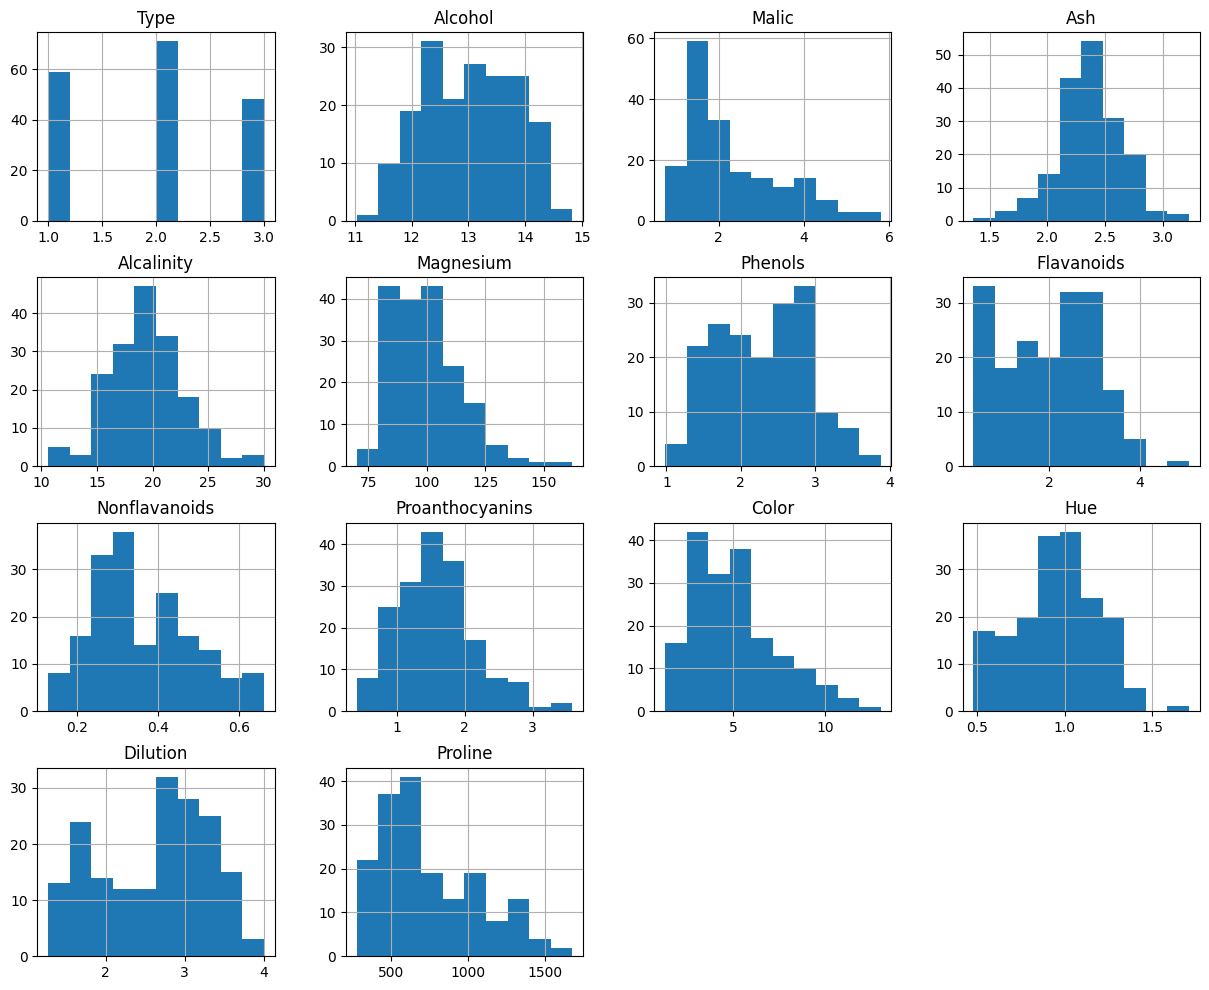

In [ ]:
#univarite analysis
wine.hist(figsize=(15,12))
plt.show()

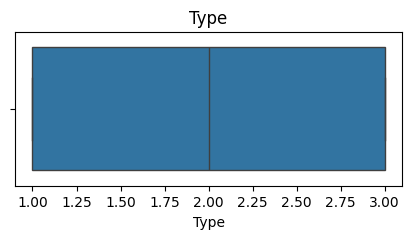

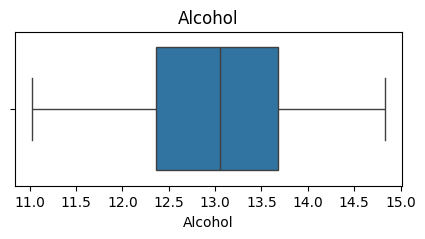

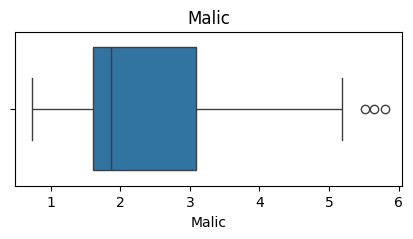

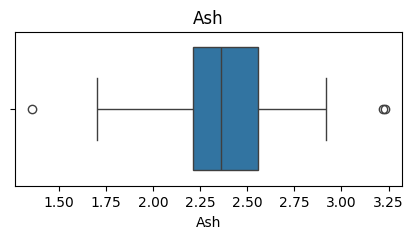

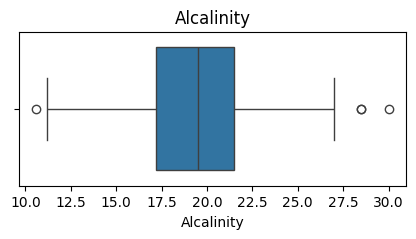

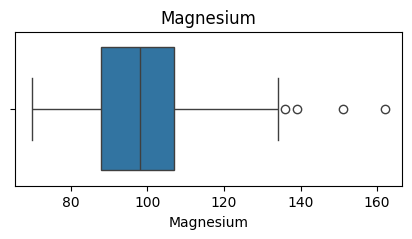

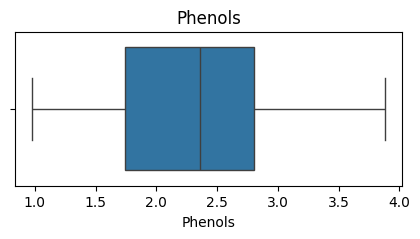

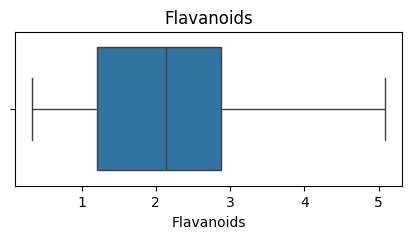

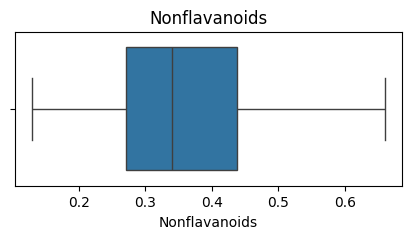

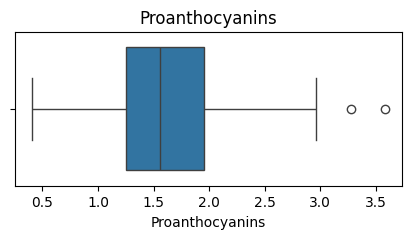

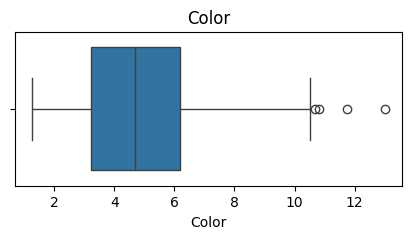

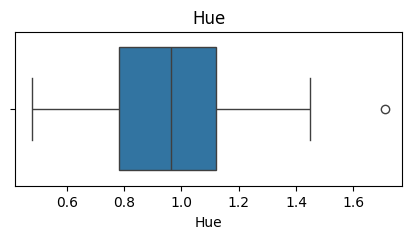

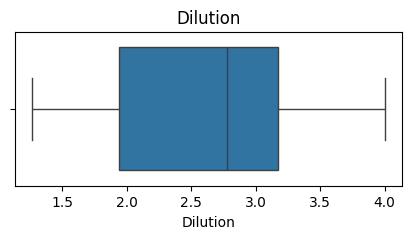

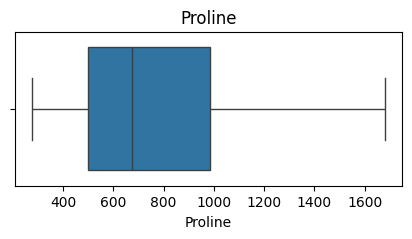

In [ ]:
#boxplot
for column in wine.columns:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=wine[column])
    plt.title(column)
    plt.show()

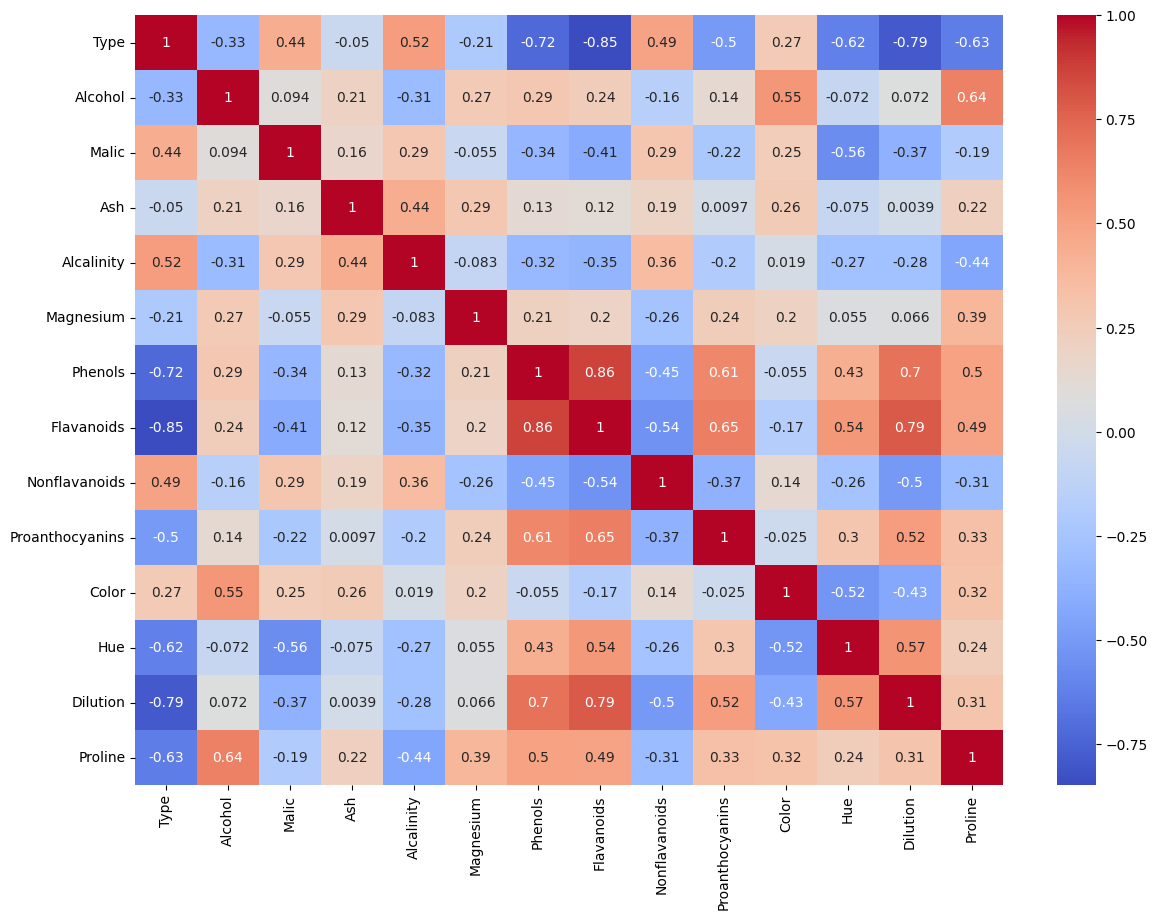

In [ ]:
#bivarite analysis
plt.figure(figsize=(14,10))
sns.heatmap(wine.corr(), annot=True, cmap='coolwarm')
plt.show()

In [ ]:
#data scaling
scaler = StandardScaler()

scaled_data = scaler.fit_transform(wine)

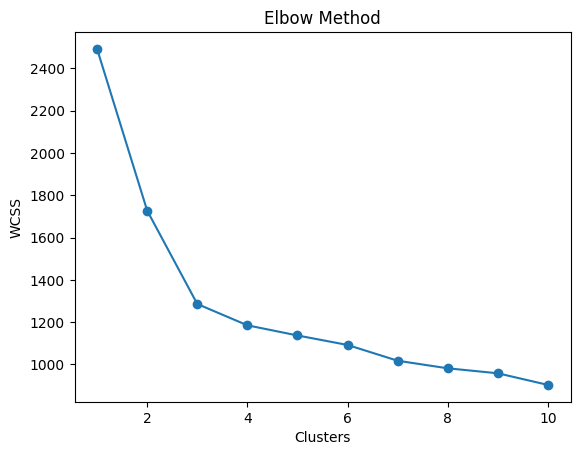

In [ ]:
#K-means clustering befor PCA
wcss = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel('Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
#final KMeans model
kmeans = KMeans(n_clusters=3, random_state=42)

clusters_before = kmeans.fit_predict(scaled_data)

wine['Cluster_Before_PCA'] = clusters_before

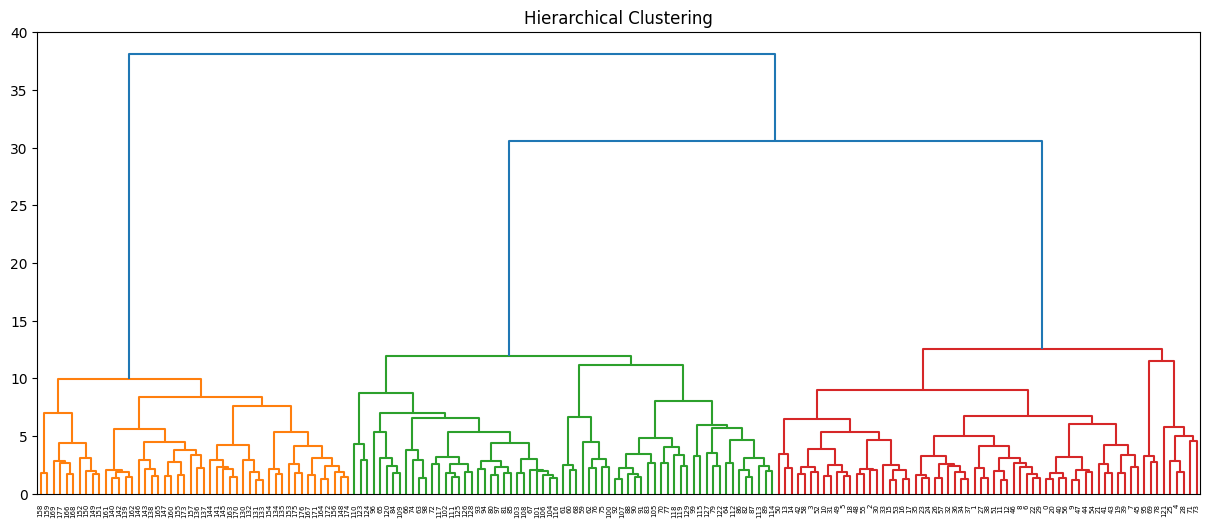

In [ ]:
#hierarchical clustering before PCA
linkage_matrix = linkage(scaled_data, method='ward')

plt.figure(figsize=(15,6))
dendrogram(linkage_matrix)
plt.title('Hierarchical Clustering')
plt.show()

In [ ]:
#PCA modeling
pca = PCA()

pca_data = pca.fit_transform(scaled_data)

In [ ]:
#varience ration
pca.explained_variance_ratio_

array([0.39542486, 0.17836259, 0.10329102, 0.06627984, 0.06267875,
       0.0480556 , 0.03955707, 0.02500244, 0.02103871, 0.01873615,
       0.01613203, 0.01205691, 0.00925458, 0.00412945])

In [ ]:
#cumulative variance
np.cumsum(pca.explained_variance_ratio_)

array([0.39542486, 0.57378745, 0.67707846, 0.74335831, 0.80603706,
       0.85409266, 0.89364973, 0.91865217, 0.93969088, 0.95842703,
       0.97455906, 0.98661596, 0.99587055, 1.        ])

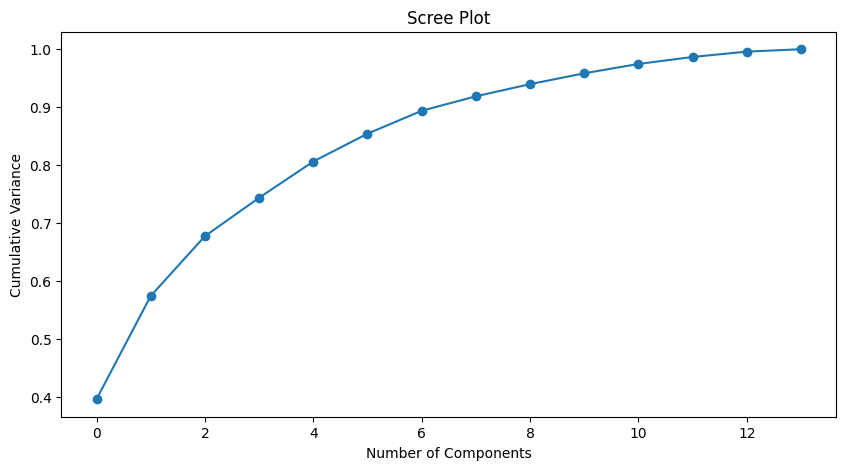

In [ ]:
#scree plot
plt.figure(figsize=(10,5))

plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')

plt.title('Scree Plot')

plt.show()

In [ ]:
#extracting first three principle
pca_final = PCA(n_components=3)

principal_components = pca_final.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1','PC2','PC3']
)

pca_df.head()

,PC1,PC2,PC3
0,-3.522934,1.453098,-0.164795
1,-2.528858,-0.330019,-2.026707
2,-2.785029,1.036936,0.983238
3,-3.922588,2.768210,-0.174968
4,-1.407511,0.867773,2.025829


In [ ]:
#KMeans clusterig after PCA
kmeans_pca = KMeans(n_clusters=3, random_state=42)

clusters_after = kmeans_pca.fit_predict(pca_df)

pca_df['Cluster_After_PCA'] = clusters_after

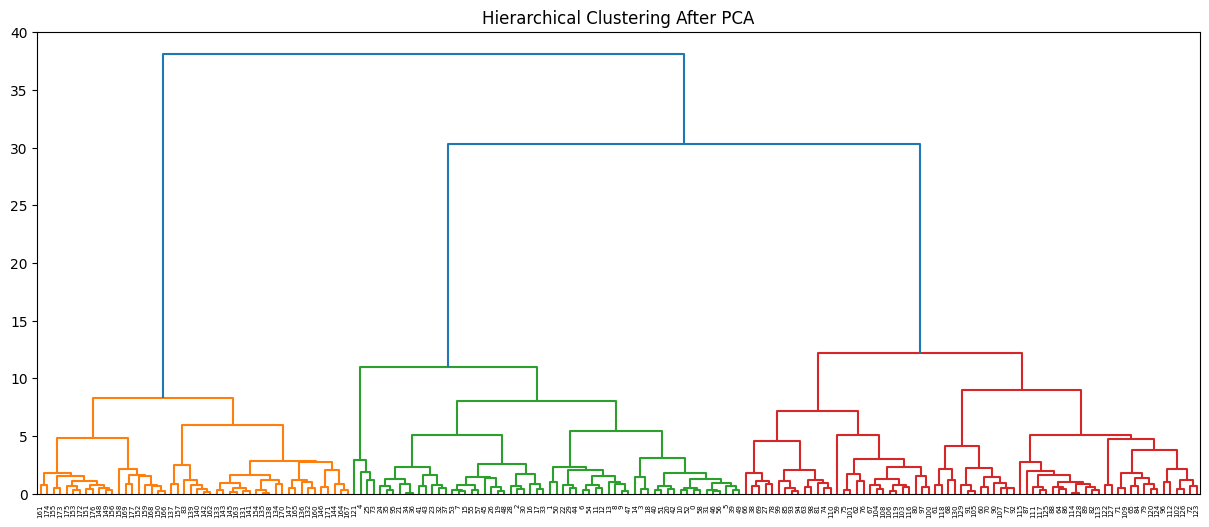

In [ ]:
#Hierarchical clustering after PCA
linkage_matrix_pca = linkage(pca_df.iloc[:,:3], method='ward')

plt.figure(figsize=(15,6))
dendrogram(linkage_matrix_pca)

plt.title('Hierarchical Clustering After PCA')

plt.show()

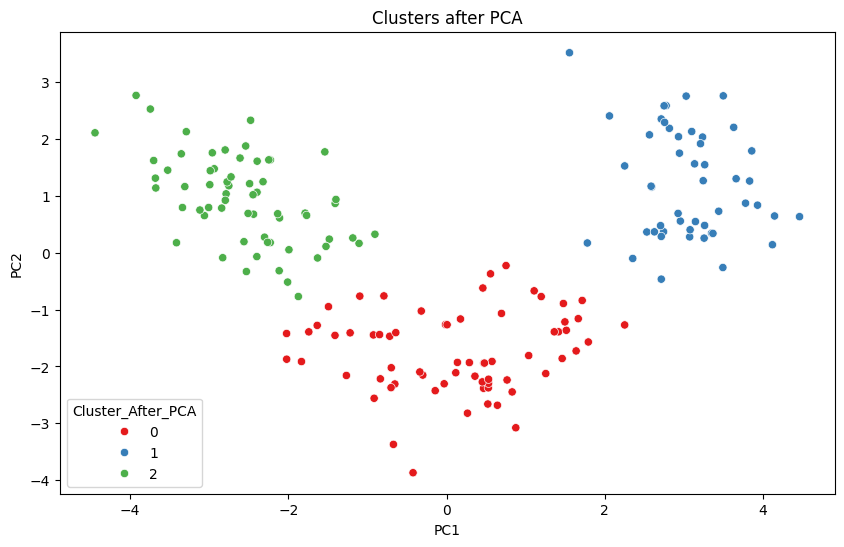

In [ ]:
#PCA visualization
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=pca_df['PC1'],
    y=pca_df['PC2'],
    hue=pca_df['Cluster_After_PCA'],
    palette='Set1'
)

plt.title('Clusters after PCA')

plt.show()

In [ ]:
#silhoutte score
score_before = silhouette_score(scaled_data, clusters_before)

score_after = silhouette_score(
    pca_df.iloc[:,:3],
    clusters_after
)

print("Before PCA:", score_before)

print("After PCA:", score_after)

Before PCA: 0.30648398324833453
After PCA: 0.4881750664935784


In [ ]:
#Interpretation
'''Interpretation
PCA reduces dimensionality while preserving maximum variance.
First 3 components explain most variance.
Clustering becomes easier and faster after PCA.'''

#Business Benefits
'''Faster analysis of wine data.
Reduced computational cost.
Better visualization of wine categories.
Helps identify similar wine groups'''

In [ ]:
#Assignment 2
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.cluster import KMeans

from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.metrics import silhouette_score

In [ ]:
heart = pd.read_csv('/content/heart disease.csv')

heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
heart.info()

heart.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
#Business Problem
'''Business Objective

To identify patient groups based on medical attributes using PCA and clustering.'''

#Business Constraints
'''Medical data complexity.
Need meaningful patient segmentation.'''

In [ ]:
#missing val
heart.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
#duplicate val
heart.duplicated().sum()


np.int64(1)

In [ ]:
#1MBD
heart.mean(numeric_only=True)

#2MBD
heart.std(numeric_only=True)
heart.var(numeric_only=True)

#3MBD
heart.skew(numeric_only=True)

#4M
heart.kurt(numeric_only=True)


,0
age,-0.542167
sex,-1.382961
cp,-1.193071
trestbps,0.929054
chol,4.505423
fbs,1.959678
restecg,-1.362673
thalach,-0.061970
exang,-1.458317
oldpeak,1.575813


In [ ]:
#EDA
heart.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


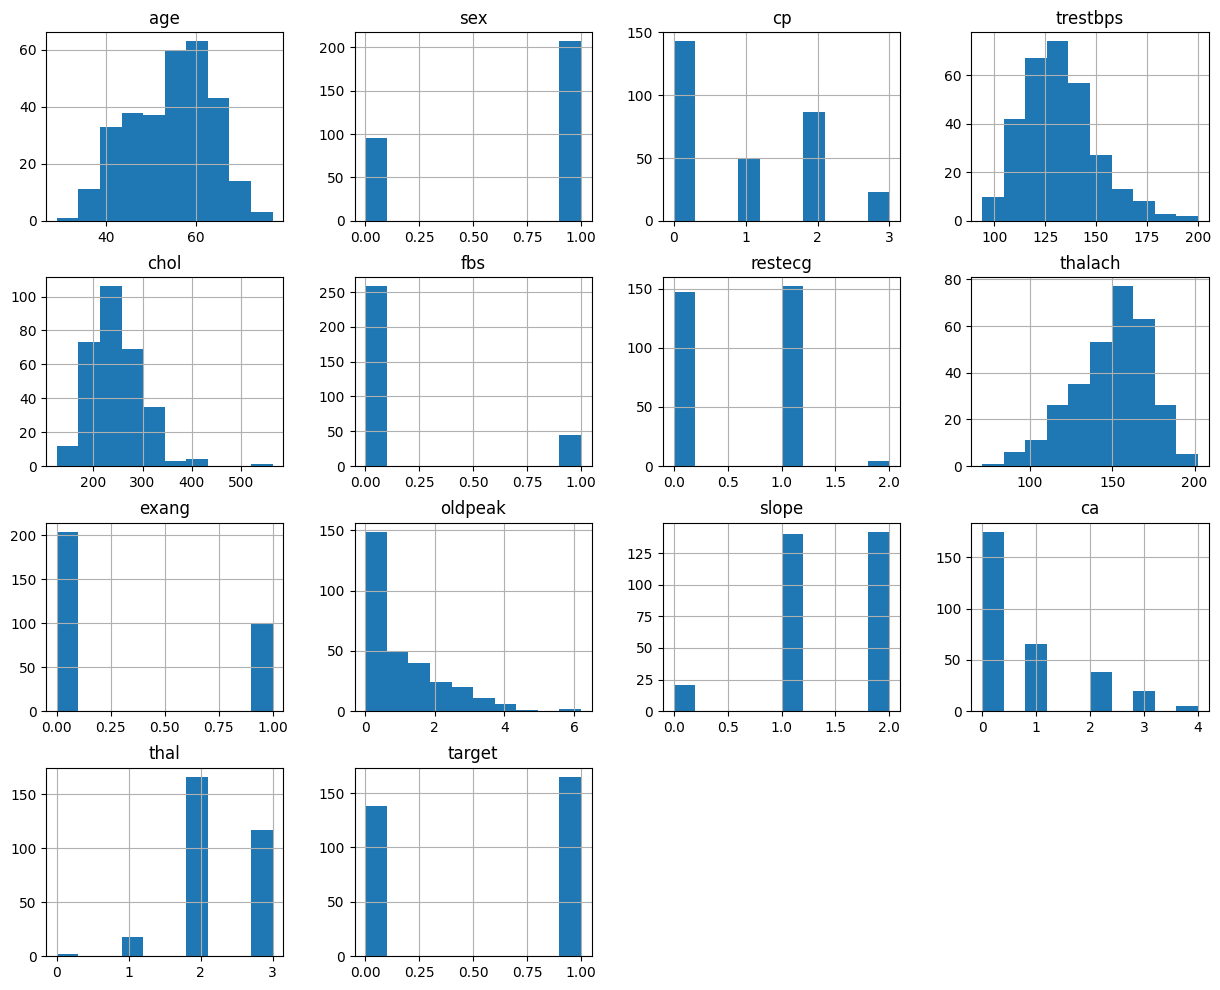

In [ ]:
#univariate analysis
heart.hist(figsize=(15,12))
plt.show()

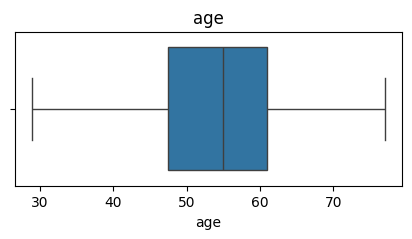

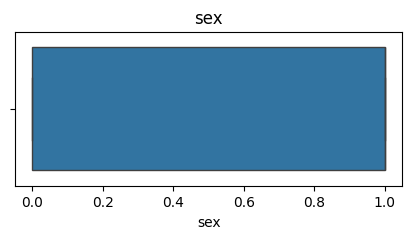

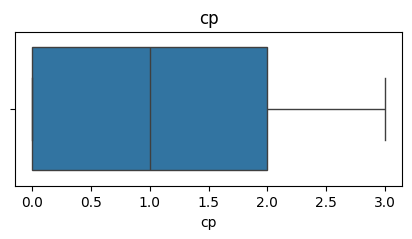

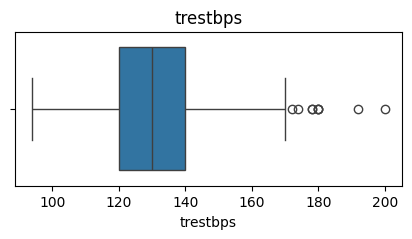

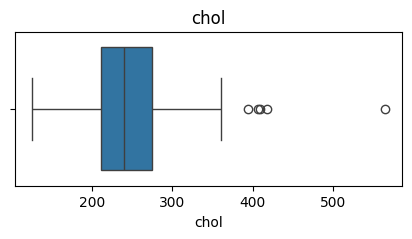

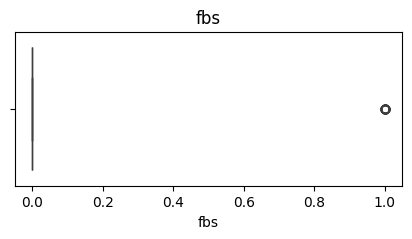

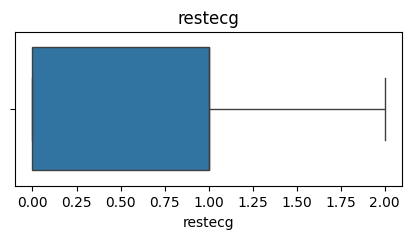

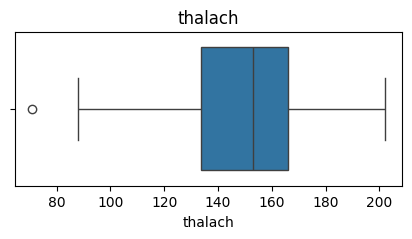

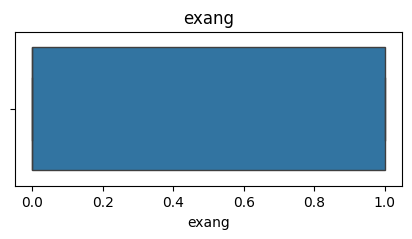

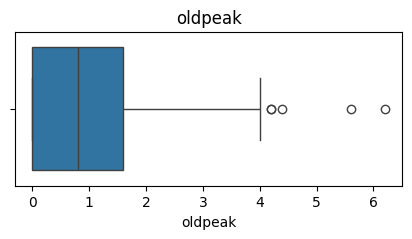

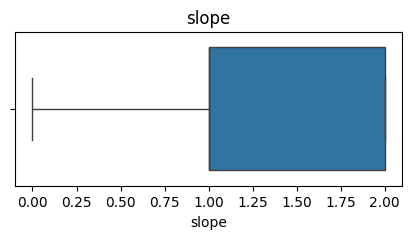

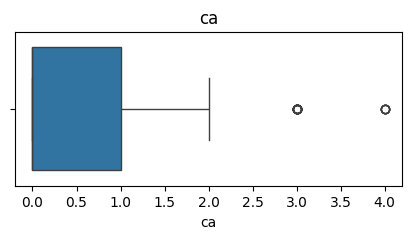

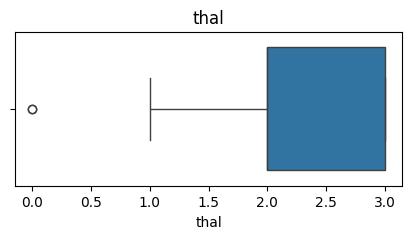

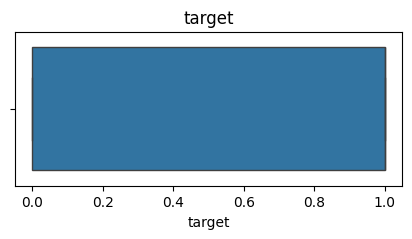

In [ ]:
#boxplot
for column in heart.columns:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=heart[column])
    plt.title(column)
    plt.show()

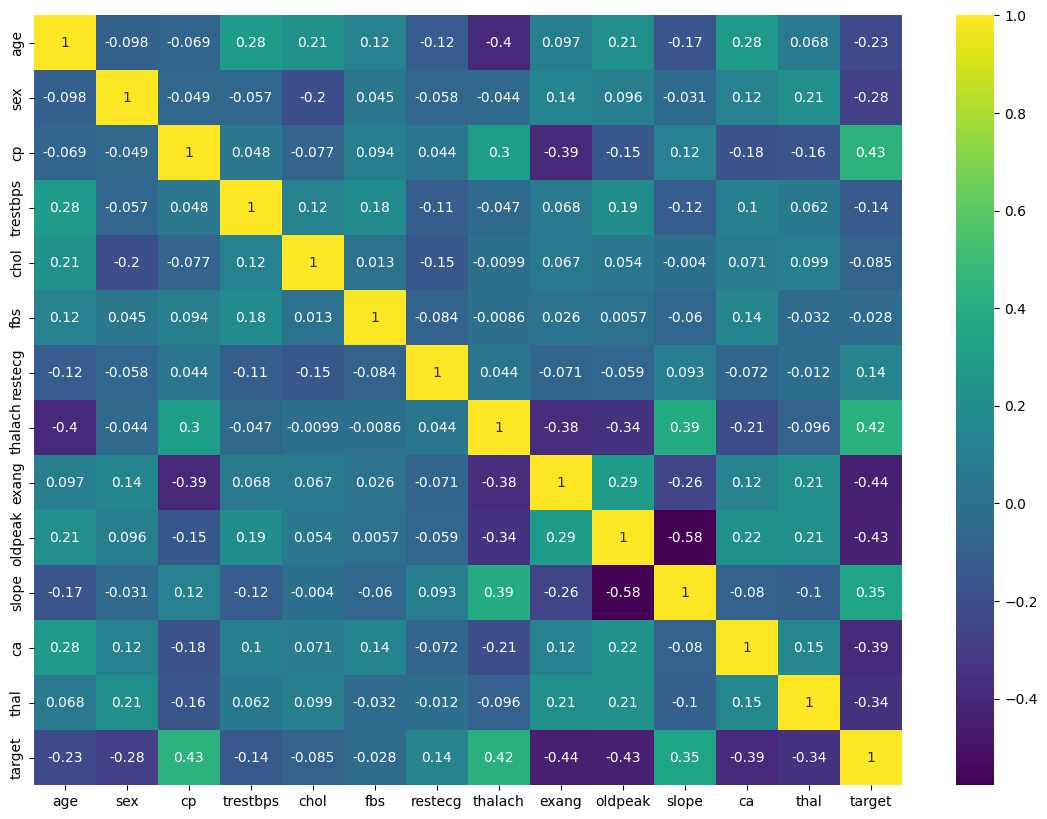

In [ ]:
#bivariate analysis
plt.figure(figsize=(14,10))
sns.heatmap(heart.corr(), annot=True, cmap='viridis')
plt.show()

In [ ]:
#data scaling
scaler = StandardScaler()

scaled_heart = scaler.fit_transform(heart)

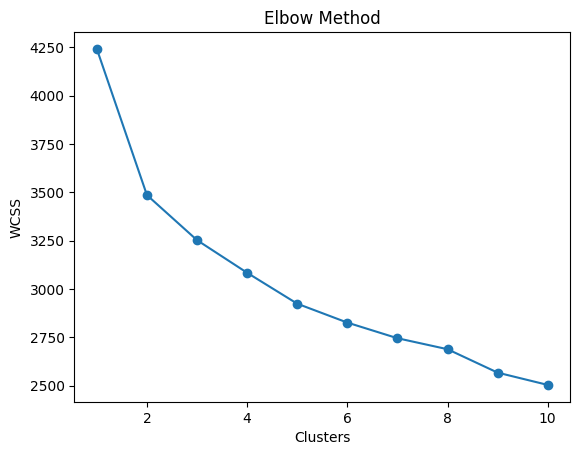

In [ ]:
#K-Means before PCA
wcss = []

for i in range(1,11):

    kmeans = KMeans(n_clusters=i, random_state=42)

    kmeans.fit(scaled_heart)

    wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.xlabel('Clusters')
plt.ylabel('WCSS')

plt.title('Elbow Method')

plt.show()

In [ ]:
#final clustering before PCA
kmeans_before = KMeans(n_clusters=3, random_state=42)

clusters_before = kmeans_before.fit_predict(scaled_heart)

heart['Cluster_Before_PCA'] = clusters_before

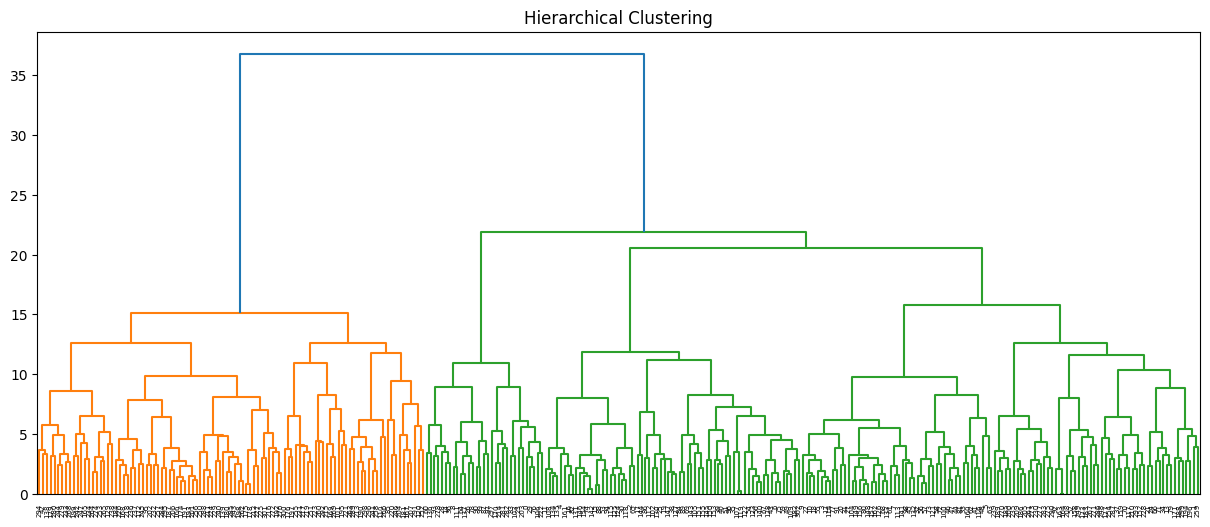

In [ ]:
#hierarchical clustering before PCA
linkage_matrix = linkage(scaled_heart, method='ward')

plt.figure(figsize=(15,6))

dendrogram(linkage_matrix)

plt.title('Hierarchical Clustering')

plt.show()

In [ ]:
#PCA model
pca = PCA()

pca_data = pca.fit_transform(scaled_heart)

In [ ]:
#Explained variance
pca.explained_variance_ratio_

array([0.23581966, 0.11229748, 0.08800207, 0.08618849, 0.07300207,
       0.06929774, 0.06165962, 0.05543521, 0.05208534, 0.04448005,
       0.03817159, 0.03071669, 0.02656258, 0.02628139])

In [ ]:
#cumulative variance
np.cumsum(pca.explained_variance_ratio_)

array([0.23581966, 0.34811715, 0.43611922, 0.52230771, 0.59530979,
       0.66460753, 0.72626715, 0.78170236, 0.8337877 , 0.87826775,
       0.91643934, 0.94715603, 0.97371861, 1.        ])

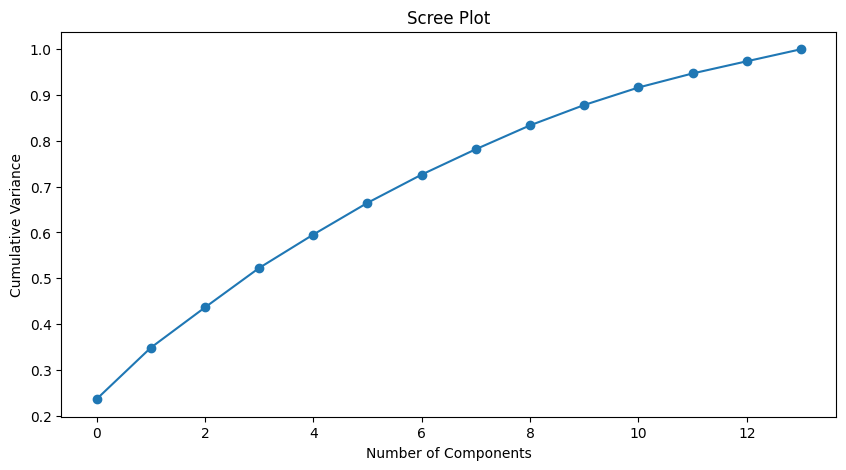

In [ ]:
#scree plot
plt.figure(figsize=(10,5))

plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')

plt.title('Scree Plot')

plt.show()

In [ ]:
#Extracting first three principal componenets
pca_final = PCA(n_components=3)

principal_components = pca_final.fit_transform(scaled_heart)

pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1','PC2','PC3']
)

pca_df.head()

,PC1,PC2,PC3
0,0.051739,2.624022,0.990054
1,0.817441,-0.730375,-0.235928
2,2.057599,-0.039098,-0.519839
3,1.903043,-0.596701,0.076204
4,0.768371,0.412545,-2.187455


In [ ]:
#K-Means after PCA
kmeans_after = KMeans(n_clusters=3, random_state=42)

clusters_after = kmeans_after.fit_predict(pca_df)

pca_df['Cluster_After_PCA'] = clusters_after

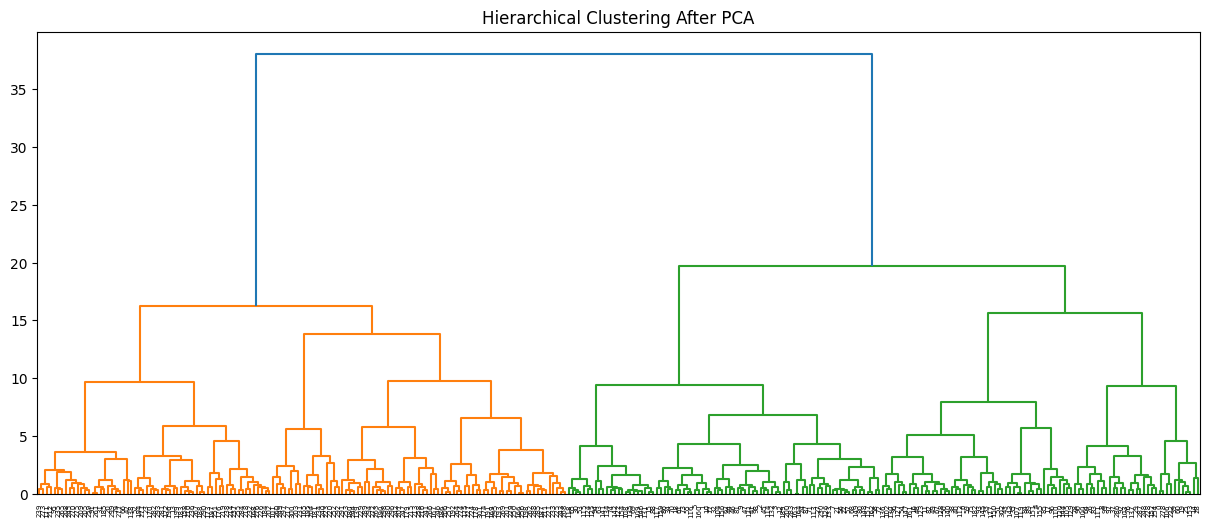

In [ ]:
#Hierarchical clustring after PCA
linkage_matrix_pca = linkage(
    pca_df.iloc[:,:3],
    method='ward'
)

plt.figure(figsize=(15,6))

dendrogram(linkage_matrix_pca)

plt.title('Hierarchical Clustering After PCA')

plt.show()

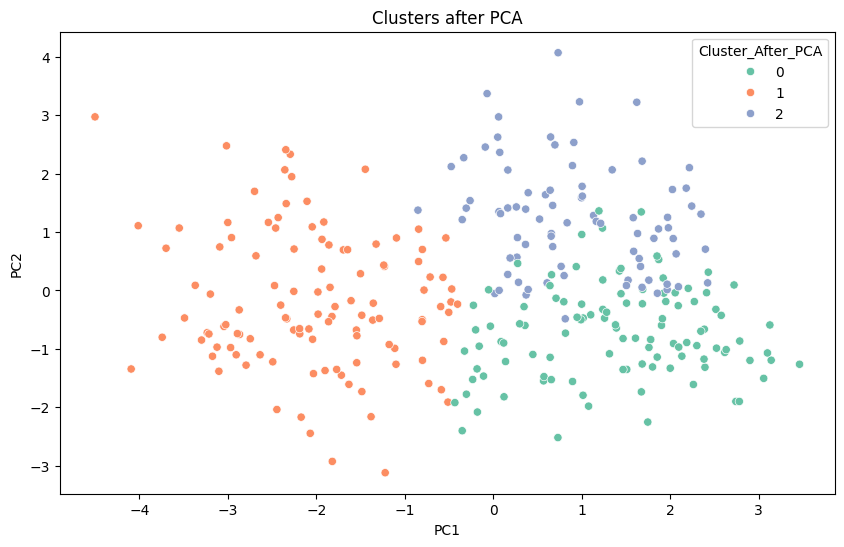

In [ ]:
#PCA visualization
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=pca_df['PC1'],
    y=pca_df['PC2'],
    hue=pca_df['Cluster_After_PCA'],
    palette='Set2'
)

plt.title('Clusters after PCA')

plt.show()

In [ ]:
#silhouttee score
score_before = silhouette_score(
    scaled_heart,
    clusters_before
)

score_after = silhouette_score(
    pca_df.iloc[:,:3],
    clusters_after
)

print("Before PCA:", score_before)

print("After PCA:", score_after)

Before PCA: 0.12702121990286502
After PCA: 0.31084195499149503


In [ ]:
#Interpretation
'''Interpretation
PCA reduces dimensionality of patient data.
Major information is retained in first 3 components.
Clustering becomes computationally efficient.'''

#Business Benefits
'''Helps identify patient categories.
Faster medical analytics.
Better treatment planning.
Supports clinical decision making'''